This script will attempt to reproduce the 1D random walk example using a simplified Temporal Difference (TD) model called **TD(0)**.

After performing an iteration $$S_0 \xrightarrow{A_1,R_1} S_1 $$, the current value estimate for the next possible state is computed based off the immediate reward (here $R_1$) and the current estimated value for the next step $S_{t+1}$ for all possible states

TD(0) makes the following approximation : $$G_{t+1} \approx V(S_{t+1}) = V(s') \iff G_{t} = R_{t+1} + \gamma \cdot V(s')$$

The TD target is a generic update as follows :

$$ V(s_t) \leftarrow V(s_t) + \alpha \left[\text{target} - V(s_t) \right] $$

$$ V(s_t) \leftarrow V(s_t) + \alpha \left[\underbrace{R_{t+1} + \gamma \cdot V(s') - V(s_t)}_{\text{TD Error}} \right] $$

With $$S_t \xrightarrow{R_{t+1}} S_{t+1} $$

Note : this is POLICY EVALUATION : we are **on-policy** and the policy is fixed, we only carry an evaluation of the state-value function for each state

In [25]:
# TD(0) Random Walk Example
import numpy as np

STATES = range(10) # to show how TD(0) performs better in longer episodes we increase the size of the 1D array grid from 5 to 10
alpha = 0.2
gamma = 0.99

V = [0 for state in STATES] # initialize the value state function for each state

def take_action(state,action):
    return state + action

def execute_policy():
    return np.random.choice([-1, 1], p=[0.5, 0.5])

def get_reward(state):
    if state == 9:
        return 1
    return 0

def update_V(state, next_state):
    reward = get_reward(next_state)

    V[state] = V[state] + alpha * (
        reward + gamma * V[next_state] - V[state]
    )

# initialize state at 5. We can try other combinations

episodes = 1000

for episode in range(episodes):

    state = np.random.choice(STATES)

    while state not in [0, 9]:

        action = execute_policy()
        next_state = take_action(state, action)

        update_V(state, next_state)

        state = next_state




[0, 0.04405750728199674, 0.16530415257148112, 0.2454166369000993, 0.31171887742196797, 0.43656944688727967, 0.6224202566441777, 0.7495615058570406, 0.9351259128433991, 0]


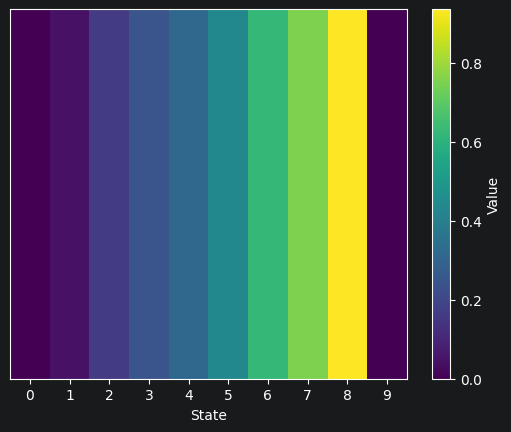

In [26]:
import matplotlib.pyplot as plt
import numpy as np
print(V)
V = np.array(V)
plt.imshow(V.reshape(1, -1), aspect='auto', cmap='viridis')
plt.colorbar(label='Value')

plt.yticks([])
plt.xticks(range(len(V)), range(len(V)))
plt.xlabel('State')

plt.show()

Note how $$V(9) = 0$$
State 9 is a terminal state, however the state-value function is the expected future reward _starting from_ state s. Therefore state 8 has the highest value because starting from 8 and transitioning to 9 brings maximum reward.

## Q-learning

Make a control policy that updates the state-action function to follow the optimal path

$$
Q(S_t,A_t)
\leftarrow
Q(S_t,A_t)
+
\alpha
\left[
R_{t+1}
+
\gamma \max_a Q(S_{t+1},a)
-
Q(S_t,A_t)
\right]
$$

$\max_a Q(S_{t+1},a)$ is  telling the algorithm to scan over all possible actions for that state, and pick the one with the best expected return.

This is the first practical example of an off-policy agent. The algorithm is off-policy because the update only affects the current policy. It does not use the update to direct the agent. The agent still has to derive the action from the current policy


Maximizing the entropy of a policy forces the agent to visit all states and actions. This is particularily relevant for continuous problems where the agent might steer away from the optimal policy. 